# Heavy-tailed distributions and the sample mean

Resistance measurements of a quantum-transport device average far below what a Gaussian model predicts. This notebook estimates the mean and spread of the data, samples a power-law (Pareto-type) distribution with the inversion and von Neumann (rejection) methods, and studies how the distribution of the sample mean behaves when the variance is infinite, including an empirical scaling collapse.

*Problem statements are summarised in English; my answers and code are in Portuguese.*

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import numpy.random as rd
import scipy as sci
import mpmath as mp
%matplotlib inline

## 1. Resistance measurements
### 1.1 The measured data

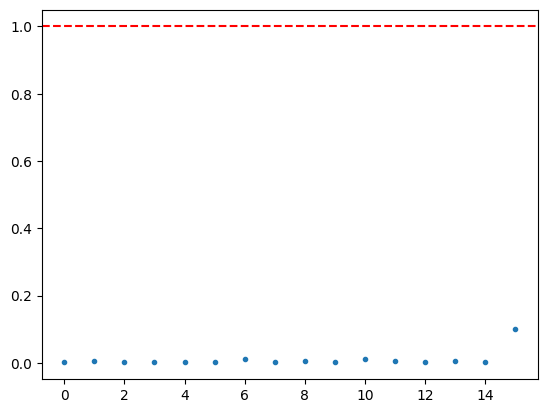

In [ ]:
points = np.array([0.00346, 0.00453, 0.00217, 0.00318, 0.00130, 0.00328, 0.0122, 0.00170, 0.00463, 0.00347, 0.01190, 0.00665, 0.00216, 0.00565, 0.00247, 0.10030])
plt.axhline(y=1.0,linestyle='--',color='r')
plt.plot(points,'.')

### 1.2 Mean and standard deviation

Para estimarmos o valor médio e a variância de uma amostra finita descorrelacionada podemos usar os respectivos estimadores:

\begin{align}
\overline{x} & = \frac{1}{N} \sum_{i = 0}^{N - 1} x_i \\
\overline{x^2} & = \frac{1}{N} \sum_{i = 0}^{N - 1} x_i^2 \\
\sigma & = \sqrt{\frac{N}{N - 1} \left( \overline{x^2} - \overline{x}^2\right)}
\end{align}

Podemos observar que o estimador médio dá um valor bem diferente do valor médio exacto. A diferença entre estes valores é bem superior ao desvio padrão medido. Também podemos observar que o desvio padrão medido é sensívelmente o dobro da média. Isto é indicador que a distribuição é muito dispersa.

In [ ]:
vmedio = np.sum(points)/len(points)
sigma2 = len(points)/(len(points) - 1) *(np.sum(points**2)/len(points) - vmedio ** 2)
sigma = np.sqrt(sigma2)
print("Valor Medio = ", vmedio)
print("Desvio Padrão = ", sigma)

Valor Medio =  0.010565625
Desvio Padrão =  0.024148792369736976


### 1.3 Percentile of the measured mean under a Gaussian model

O probabilidade é de ter um valor inferior ao estimador medido é extremamente pequena. Para a avaliar recorremos à avaliação da função erro,
\begin{align}
C(x) &= \int_{-\infty}^{x} dx \frac {e^{-\frac{(x - \mu)^2}{2 \sigma^2}}}{\sqrt{2\pi \sigma^2}}\\
 &=\frac{1}{2} \left( 1 + \text{erf}\left(\frac{x - \mu }{\sqrt{2 \sigma^2}}\right)\right) 
\end{align}

A função erro será negativa e muito próximo de *-1*. Isto significa que se não tivermos casas decimais suficientes o resultado que obteremos será zero. Para conseguir estimar a ordem de grandeza da probabilidade de ser menor que o estimador usamos o módulo mpmath.
Como podemos ver, caso a distribuição fosse gaussiana seria muito pouco provável medir este valor pois corresponde a percentil *Infinitesimal*.

In [ ]:
mp.mp.prec = 4000
mp.nprint((mp.erf( (vmedio - 1)/sigma /np.sqrt(2)) + 1)/2)

2.84865e-367


## 2. Random number generation
### 2.1 Inversion method, solved with Newton–Raphson

No método de inversão é necessário inverter a função cumulativa. A função cumulativa desta distribuição é 
\begin{align}
C(x) & = \int_{-\infty}^{x} dx' \rho(x') \\
    & = 1 - \frac{p}{x^{\alpha - 1}} - \frac{1-p}{x^\alpha} 
\end{align}

Este procedimento torna-se demasiado dispendioso e pode levantar a questões de precisão. 
Nesta célula iremos apresentar a aplicação do método de Newton-Raphson para inverter esta distribuição (Não era pedido para fazer isto!).

Podemos verificar que estimando a distribuição de probabilidade a partir de histogramas é possível concluir que estamos a gerar a distribuição correcta. 

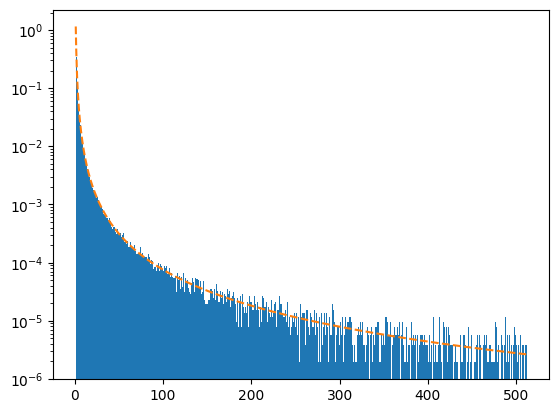

In [ ]:
def rho(x, alpha):
    p = 0.9
    return p * (alpha - 1)/x**alpha + (1 - p)*alpha/x**(alpha + 1)

    
def get_x(y, alpha):
    x = 1
    p = 0.9
    delta = 1
    while(np.abs(delta) > 1E-9):
        df = (alpha - p*x + p*(x - 1) * alpha)/x**(1 + alpha)
        f = 1 -y - p/x**(alpha - 1) - (1 - p)/x**alpha
        delta = f/df
        x = x - delta
    return x

sample = rd.random_sample(2**20)
s2 = 0.0 * sample
for i, x in enumerate(sample):
    s2[i] = get_x (x, 2.05)
z1, z2, z3 = plt.hist(s2,bins = 1024, range=(1,512),density=True)
alpha = 2.05
x = np.linspace(1, 512, 1024)
plt.plot(x, rho(x,2.05) ,'--')
plt.yscale('log')

### 2.2 von Neumann rejection with an exponential proposal

No método de von Neumann propõe-se um estado no domínio com uma distribuição de probabilidade de escolha, $E(x)$, e aceita-se a amostra com o o quociente $P_A = \rho(x)/E(x)$. O quociente destas duas distribuições é uma função contínua e maior que zero. Contudo pode não ser menor que um. Normalmente, dividimos por um número de modo a garantir que é sempre menor que um.

Aqui está o problema do uso da distribuição exponencial. O valor máximo do quociente é sempre infinito e para $x\to+\infty$.
Para ilustrar este problema usamos vários valores de $\lambda$ e um máximo fixo. Na primeira figura representamos o quociente e identificamos o ponto onde se torna superior a um. 


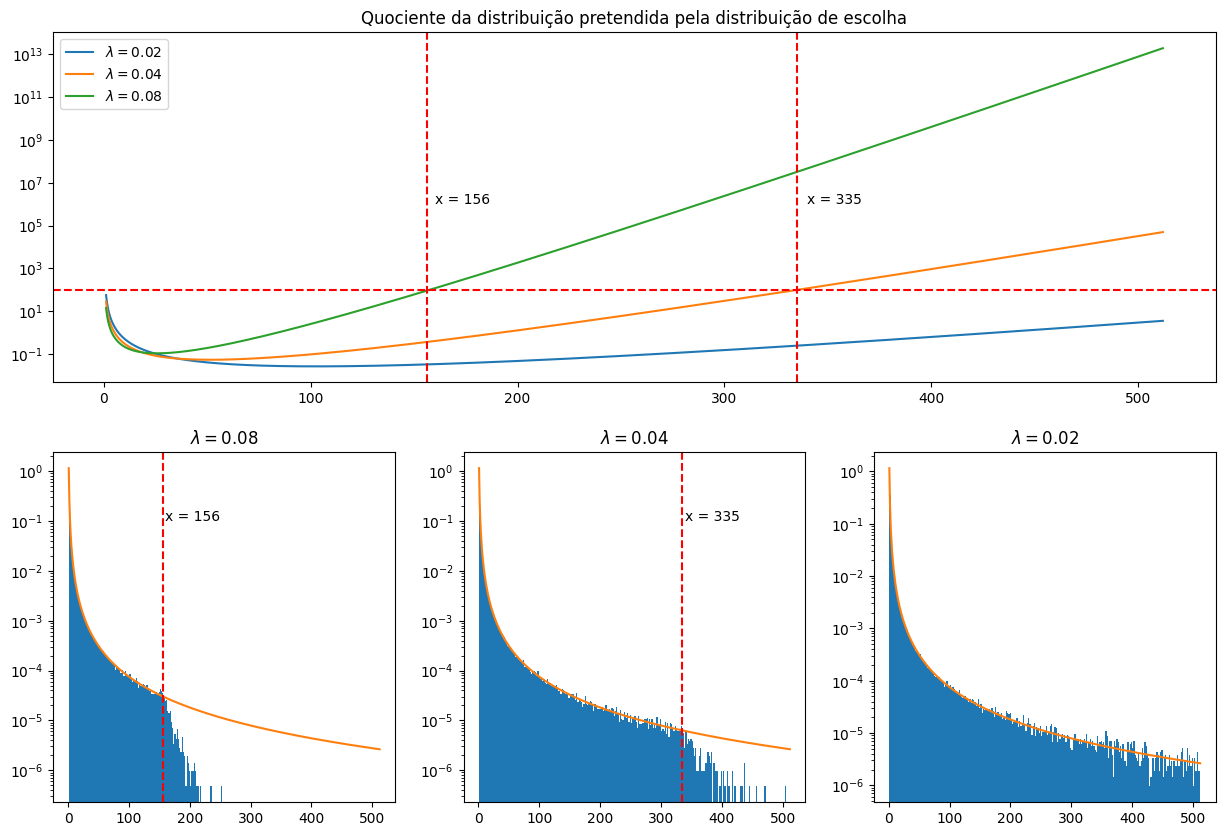

In [ ]:
def Esc(x, lamb):
    return lamb * np.exp(-lamb*(x-1))

fig = plt.figure(figsize=(15,10))
ax1 = fig.add_subplot(2, 3, (1,3))
ax2 = fig.add_subplot(2, 3, 4)
ax3 = fig.add_subplot(2, 3, 5)
ax4 = fig.add_subplot(2, 3, 6)

x = np.linspace(1,512,1000)
ax1.set_title("Quociente da distribuição pretendida pela distribuição de escolha")
ax1.plot(x, rho(x,2.05)/Esc(x,0.02), label = r"$\lambda = 0.02$")
ax1.plot(x, rho(x,2.05)/Esc(x,0.04), label = r"$\lambda = 0.04$" )
ax1.plot(x, rho(x,2.05)/Esc(x,0.08), label = r"$\lambda = 0.08$" )
ax1.axhline(y=100, linestyle='--',color='r')


ax1.axvline(x=156,linestyle='--',color='r')
ax1.text(160, 1000000, "x = 156")

ax1.axvline(x=335,linestyle='--',color='r')
ax1.text(340, 1000000, "x = 335")
ax1.set_yscale('log')
ax1.legend()



def gerar_exponencial(M, alpha, lamb, maximo):
    final = np.array([],dtype=float)
    
    while(final.size < M):
        amostra = 1 - np.log(rd.random_sample(M))/lamb
        p = rho(amostra, alpha)/Esc(amostra, lamb)/maximo
        resultados, = np.where(rd.random_sample(M) < p)
        resultados = amostra[resultados]
        final= np.concatenate((final,resultados))    
    return final
    

amostra = gerar_exponencial(2**20 , 2.05, 0.08, 100)
z1,z2,z3 = ax2.hist(amostra, bins=256, range=(1,512),density=True)
ax2.set_title(r"$\lambda = 0.08$")
ax2.plot(x, rho(x,2.05))
ax2.axvline(x=156,linestyle='--',color='r')
ax2.text(160, 0.1, "x = 156")
ax2.set_yscale('log')

ax3.set_title(r"$\lambda = 0.04$")
amostra = gerar_exponencial(2**20 , 2.05, 0.04, 100)
z1,z2,z3 = ax3.hist(amostra, bins=256, range=(1,512),density=True)
ax3.plot(x, rho(x,2.05))
ax3.axvline(x=335,linestyle='--',color='r')
ax3.text(340, 0.1, "x = 335")
ax3.set_yscale('log')

ax4.set_title(r"$\lambda = 0.02$")
amostra = gerar_exponencial(2**20 , 2.05, 0.02, 100)
z1,z2,z3 = ax4.hist(amostra, bins=256, range=(1,512),density=True)
ax4.plot(x, rho(x,2.05))
ax4.set_yscale('log')


### 2.3 von Neumann rejection with a Pareto proposal

No caso da distribuição de Pareto, já não se coloca o problema de convergência para um máximo uma vez que este existe e é finito no intervalo,
\begin{align}
P_A & \propto \frac{\rho(x)}{E(x)}\\
    & =  \frac{\alpha - 1}{ \tilde{\alpha} - 1} \frac{p}{x^{\alpha - \tilde{\alpha}}}
    + \frac{\alpha}{\tilde{\alpha} - 1}\frac{1 -p}{ x^{\alpha + 1 - \tilde{\alpha}}}
\end{align}
Para ser limitada e não tender para zero deveremos escolher $\alpha = \tilde{\alpha}$ (ver figura abaixo), 
\begin{equation}
P_A \propto  p + \frac{\alpha}{\alpha - 1}\frac{1 -p}{ x}
\end{equation}
Cujo máximo é $(\alpha - 1)/(\alpha - p)$.

Usando este resultado podemos fazer a simulação com aceitação máxima!

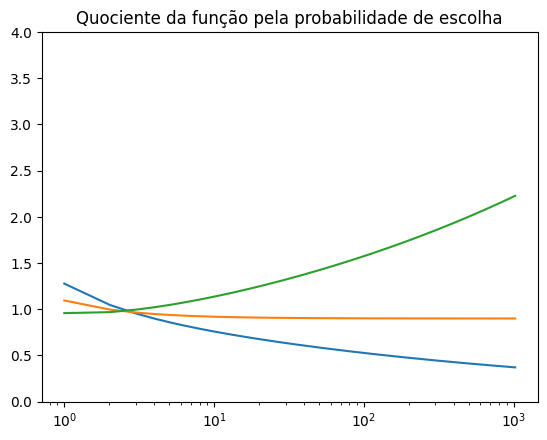

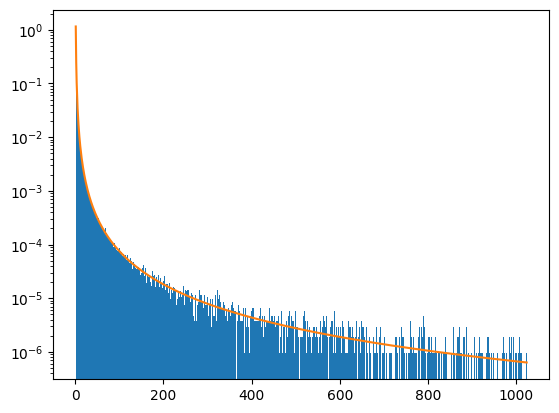

In [ ]:
def Esc(x, alpha):
    return (alpha - 1)/x**alpha

x = np.linspace(1,1024,1000)
plt.title("Quociente da função pela probabilidade de escolha")
plt.plot(x, rho(x,2.05)/Esc(x,1.9) , label=r"")
plt.plot(x, rho(x,2.05)/Esc(x,2.05) )
plt.plot(x, rho(x,2.05)/Esc(x,2.2) )
plt.xscale('log')
plt.ylim([0,4])


def gerar_Pareto(M, alpha):
    p = 0.9
    final = np.array([],dtype=float)
    maximo = (alpha - 0.9)/(alpha - 1)
    total = 0
    aceites = 0
    while(final.size < M):
        amostra = (rd.random_sample(M//8))**(1/(1 - alpha))
        prob = rho(amostra, alpha)/Esc(amostra, alpha)

        resultados, = np.where(rd.random_sample(M//8) < prob/maximo)
        resultados = amostra[resultados]
        total += M//8
        aceites += len(resultados)
        final= np.concatenate((final,resultados))    
    return aceites/total, final[:M]

plt.figure()
pA, amostra = gerar_Pareto(2**20 , 2.05)
z1,z2,z3 = plt.hist(amostra, bins=1024, range=(1,1024),density=True)
plt.plot(x, rho(x,2.05))
plt.yscale('log')


### 2.4 Sampling the distribution for several exponents α

Usando o algoritmo de von Neumann podemos gerar pontos com uma boa taxa de aceitação.
Apresentamos a comparação da distribuição de probabilidade exacta para vários valores $\alpha$ com os histogramas construídos a partir das amostras aleatórias. Também apresentamos a comparação da probabilidade de aceitação teórica,
\begin{align}
P_A &= \int_1^{+\infty} dx E_\alpha (x) P_\alpha(A|x) =  \frac{\alpha - 1}{ \alpha - p} 
\end{align}
onde $ P_\alpha(A|x) = \rho_\alpha(x) /E_\alpha(x)/max) $
Nesta célula calculamos para os diferentes valores de $\alpha$ a distribuição gerada e a sua comparação com a distribuição exacta. Também fizemos uma medida da frequência de aceitação e comparamos a probabilidade de aceitação teórica. 

0.9127426147460938 0.9130434782608695
0.9283125135633681 0.9285714285714285
0.9395853678385416 0.9393939393939393
0.9472003512912326 0.9473684210526315
0.953720940483941 0.9534883720930232


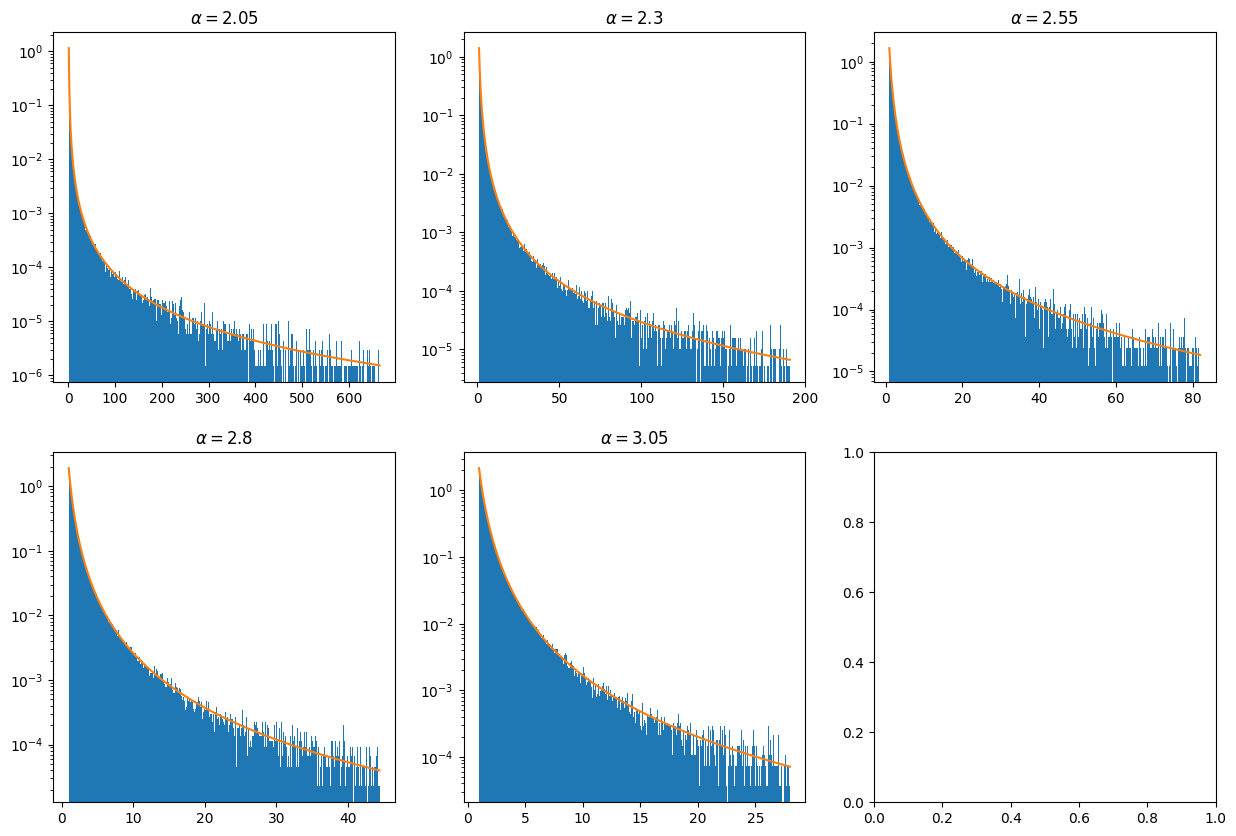

In [ ]:

M = 2**20
fig, axs = plt.subplots(2,3,figsize=(15,10))

for i, alpha in enumerate([2.05, 2.30, 2.55, 2.80, 3.05]):
    x = np.linspace(1, get_x(1 - 1024 * 2.0**(-20),alpha),1024)
    PA, amostra = gerar_Pareto(M , alpha)
    print(PA, (alpha - 1)/(alpha - 0.9) )
    z1,z2,z3 = axs[i//3, i%3 ].hist(amostra, bins=1024, range=(1,get_x(1 - 1024 * 2.0**-20, alpha)),density=True)
    axs[i//3, i%3 ].set_title(r"$\alpha = $" + str(alpha))
    axs[i//3, i%3 ].plot(x, rho(x,alpha))
    axs[i//3, i%3 ].set_yscale('log')


## 3. Distribution of the sample mean
### 3.1 Mean of the distribution as a function of α

O valor médio é dado por,
\begin{align}
\int_1^{+\infty} dx \, \rho_\alpha(x) x = p \frac{\alpha - 1}{\alpha - 2} + (1 - p) \frac{\alpha}{\alpha - 1} 
\end{align}
E só está definido para $\alpha > 2$

### 3.2 Generating samples of the mean estimator

Criei uma classe que pode gerar uma amostra muito grande e tem um método que permite *empacotar* a mostra em diferentes avaliações do estimador da média e avaliar um estimador da variância.

In [ ]:
class MyParetto:
    def __init__(self, alpha, M):
        self.M =M
        self.alpha = alpha
        self.PA, self.sample = gerar_Pareto(M, alpha)

    def build_average(self, n):
        self.Mn = self.M//n
        med = np.zeros(self.Mn)
        for i in range(n):
            data = self.sample[self.Mn*i: self.Mn*(i+1)] # Shallow Copy
            med += (data - med)/(i + 1)
        return med
            
    def build_averages(self, n):
        self.Mn = self.M//n
        med = np.zeros(self.Mn)
        var = np.zeros(self.Mn)        
    
        for i in range(n):
            data = self.sample[self.Mn*i: self.Mn*(i+1)] # Shallow Copy
            med_old = med.copy()
            med += (data - med)/(i + 1)
            var += ((data - med )* (data - med_old) - var)/(i + 1)
        return med , var * n/(n-1)        



### 3.3 Distributions of the rescaled mean and of the standard deviation
#### α = 2.05

Para este valor do expoente $\alpha$ o valor médio existe (19.095) mas a variância é infinita. Com estes tamanhos de amostra não conseguimos observar a convergência do valor mais provável do estimador para a próximidade do valor médio. Indicando que pecisamos de ter uma amostra muito maior para observar esta convergência. A variância da amostra está claramente a crescer com o aumento da tamanho (esperamos este comportamento pois a variância é infinita).

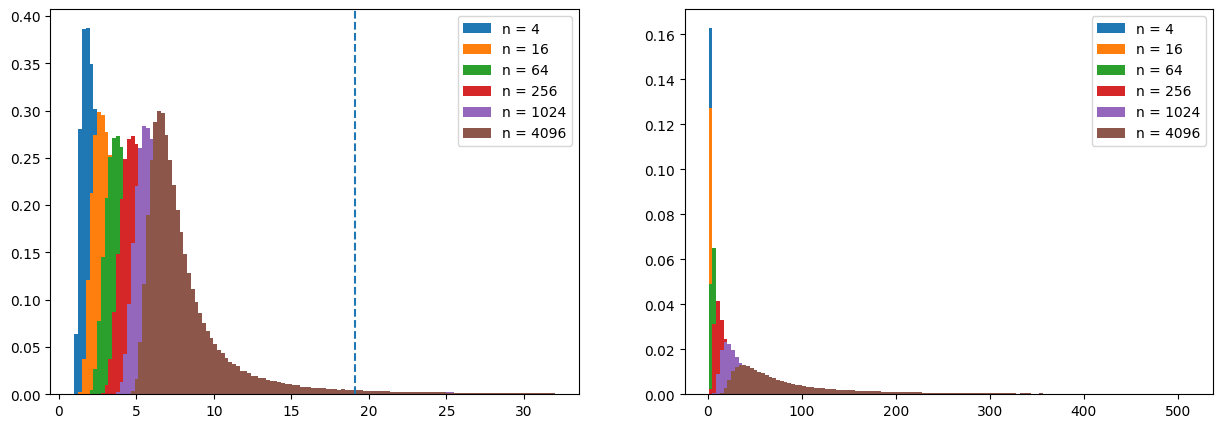

In [ ]:
fig, ax = plt.subplots(1,2,figsize=(15,5))
myp205 = MyParetto(2.05, 2**30)

for n in [4, 16, 64,256,1024,4096]:
    m, v = myp205.build_averages(n)
    x1,x2,x3 = ax[0].hist(m, bins=128, range=(1,32),density=True, label="n = " + str(n))
    x1,x2,x3 = ax[1].hist(np.sqrt(v), bins=128, range=(1,512),density=True, label="n = " + str(n))
ax[0].axvline(x=19.095,linestyle='--')
ax[0].legend()
ax[1].legend()

#    plt.yscale('log')

#### α = 2.30

Para este valor do expoente $\alpha$ o valor médio existe (4.077) mas a variância é infinita. Podemos ver que para as amostras simuladas já conseguimos ver a distribuição da média a aproximar-se do valor médio. Mas note-se que a distribuição da soma contínua muito assimétrica e não está a convergir para uma gaussiana (a variância é infinita).

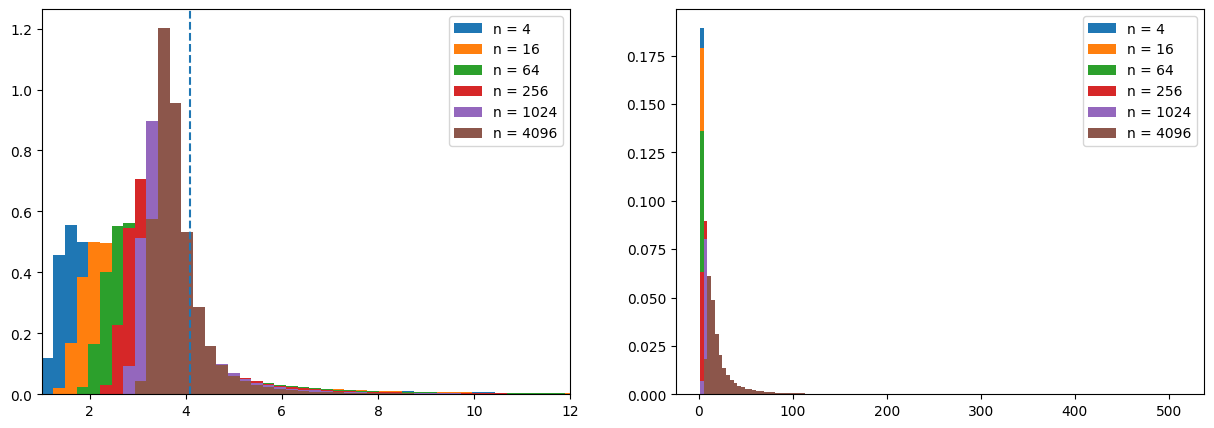

In [ ]:
fig, ax = plt.subplots(1,2,figsize=(15,5))
myp230 = MyParetto(2.30, 2**30)

for n in [4, 16, 64,256,1024,4096]:
    m, v = myp230.build_averages(n)
    x1,x2,x3 = ax[0].hist(m, bins=128, range=(1,32),density=True, label="n = " + str(n))
    x1,x2,x3 = ax[1].hist(np.sqrt(v), bins=128, range=(1,512),density=True, label="n = " + str(n))
ax[0].axvline(x=4.077,linestyle='--')
ax[0].set_xlim([1,12])
ax[0].legend()
ax[1].legend()


#### α = 2.55

Para este valor do expoente $\alpha$ o valor médio existe (2.7088) mas a variância é infinita. Podemos ver que para as amostras simuladas já conseguimos ver a distribuição da média a aproximar-se do valor médio. Mas note-se que a distribuição da soma contínua muito assimétrica e não está a convergir para uma gaussiana (a variância é infinita).

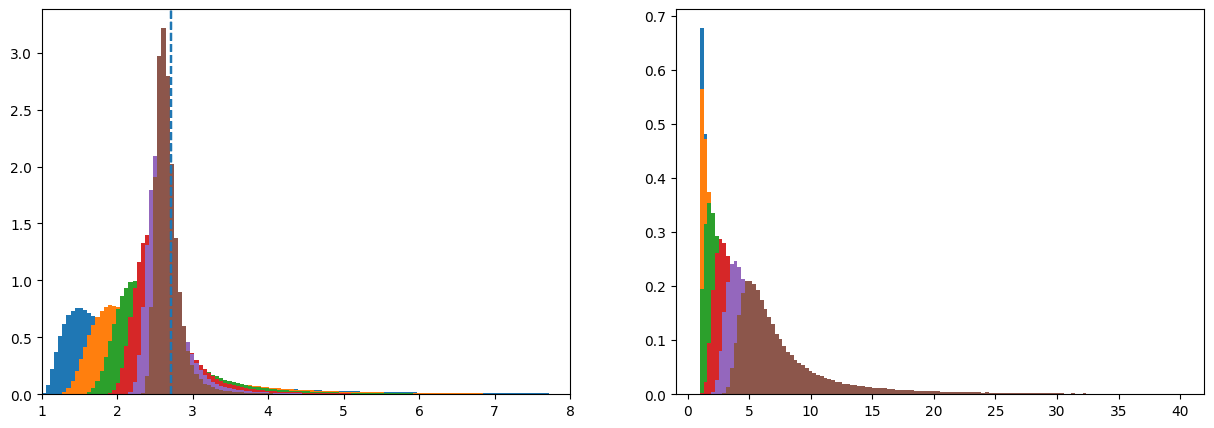

In [ ]:
fig, ax = plt.subplots(1,2,figsize=(15,5))
myp255 = MyParetto(2.55, 2**30)

for n in [4, 16, 64,256,1024,4096]:
    m, v = myp255.build_averages(n)
    x1,x2,x3 = ax[0].hist(m, bins=128, range=(1,8),density=True)
    x1,x2,x3 = ax[1].hist(np.sqrt(v), bins=128, range=(1,40),density=True)
    ax[0].axvline(x=2.7088,linestyle='--')
    ax[0].set_xlim([1,8])
#    plt.yscale('log')

#### α = 2.80

Para este valor do expoente $\alpha$ o valor médio existe (2.18056) mas a variância é infinita. Podemos ver que para as amostras simuladas já conseguimos ver a distribuição da média a aproximar-se do valor médio. Mas note-se que a distribuição da soma contínua muito assimétrica e não está a convergir para uma gaussiana (a variância é infinita).

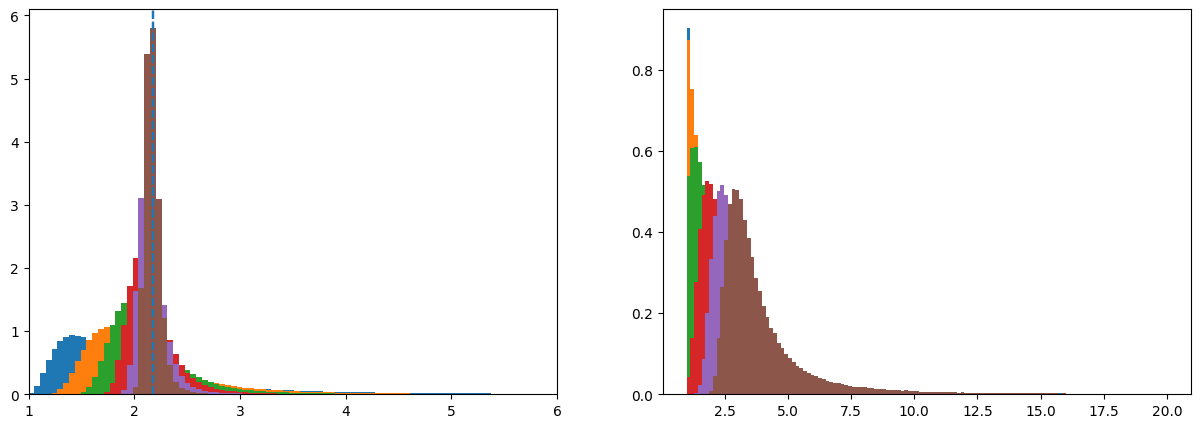

In [ ]:
fig, ax = plt.subplots(1,2,figsize=(15,5))
myp280 = MyParetto(2.80, 2**30)

for n in [4, 16, 64,256,1024,4096]:
    m, v = myp280.build_averages(n)
    x1,x2,x3 = ax[0].hist(m, bins=128, range=(1,8),density=True)
    x1,x2,x3 = ax[1].hist(np.sqrt(v), bins=128, range=(1,20),density=True)
    ax[0].axvline(x=2.18056,linestyle='--')
    ax[0].set_xlim([1,6])
#    plt.yscale('log')

#### α = 3.05

Para este valor do expoente $\alpha$ o valor médio existe (1.90592). Para este valor de $\alpha$ a variância passou a ser finita e podemos ver que a distribuição do desvio padrão quase não muda com o aumento do tamanho da amostra. Também podemos notar que a distribuição de probabilidade está a ficar mais concentrada em **torno** do valor médio. Com o aumento do tamanho do estiamdor esperamos que convirja para uam gaussiana. 

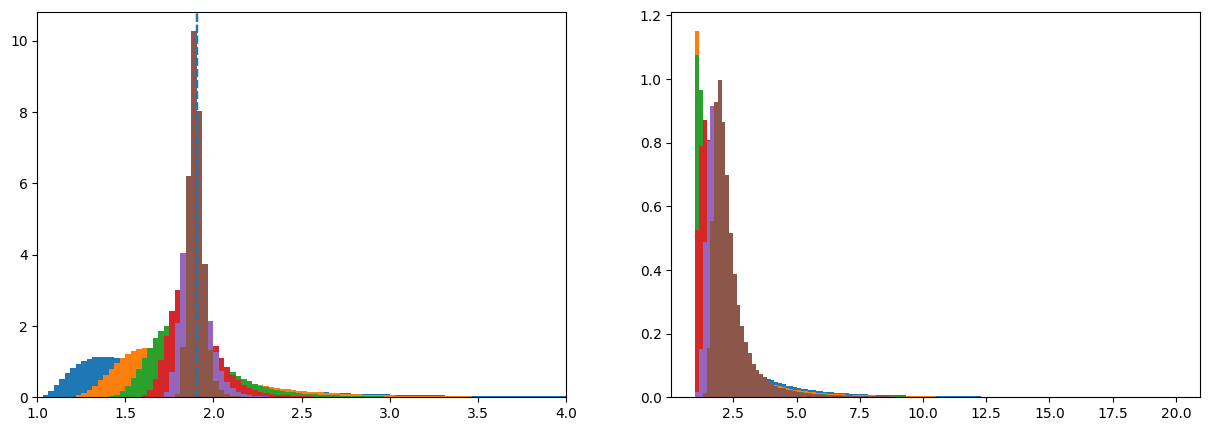

In [ ]:
fig, ax = plt.subplots(1,2,figsize=(15,5))
myp305 = MyParetto(3.05, 2**30)

for n in [4, 16, 64,256,1024,4096]:
    m, v = myp305.build_averages(n)
    x1,x2,x3 = ax[0].hist(m, bins=128, range=(1,5),density=True)
    x1,x2,x3 = ax[1].hist(np.sqrt(v), bins=128, range=(1,20),density=True)
    ax[0].axvline(x=1.90592,linestyle='--')
    ax[0].set_xlim([1,4])
#    plt.yscale('log')

### 3.4 Scaling collapse of the distribution of the mean

No código abaixo encontramos empiricamente os expoentes através do colapso das distribuições de probabilidade da variável reescalado. Conseguimos encontrar valores aproximados de $\gamma$ para todos os valores de $\alpha$. Note-se que este comportamento é assimptótico pelo que para fazer uma medição mais precisa seria preciso um maior número de médias. Também podemos notar que a distribuição colapsada não é sempre centrada em zero. Para $\alpha=3.05$ claramente é centrada em zero (valor médio) e deverá convergir para uma gaussiana. Contudo, para os restantes valores $\alpha$, o máximo está sempre deslocado do zero. Contudo, a dependência é assimétrica, mas com o aumento do tamanho da amostra o máximo da probabilidade pode estar tão próximo do valor médio quando queiramos. 

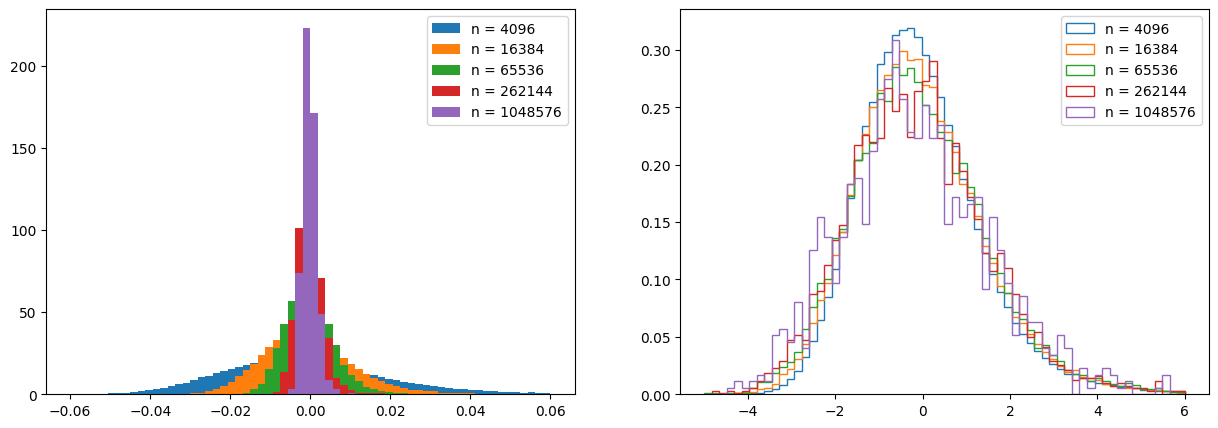

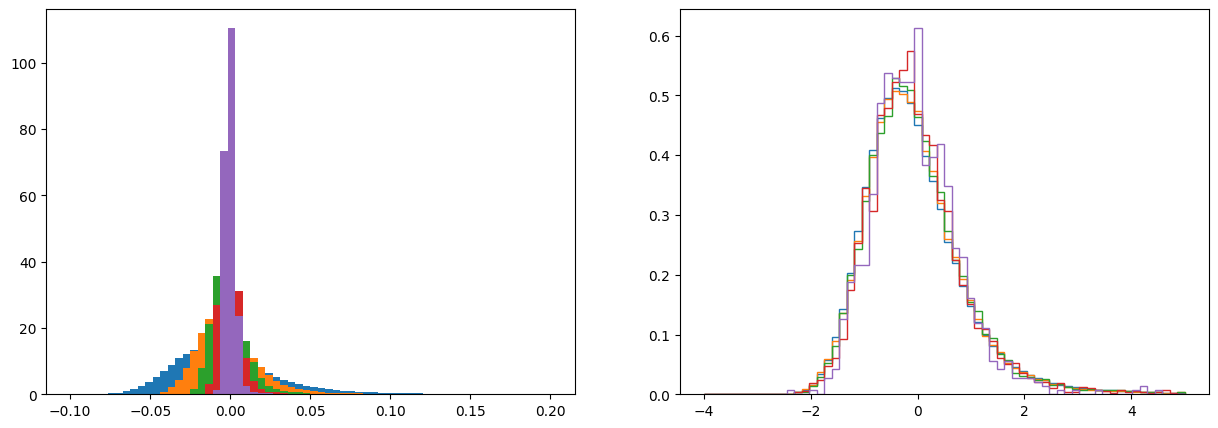

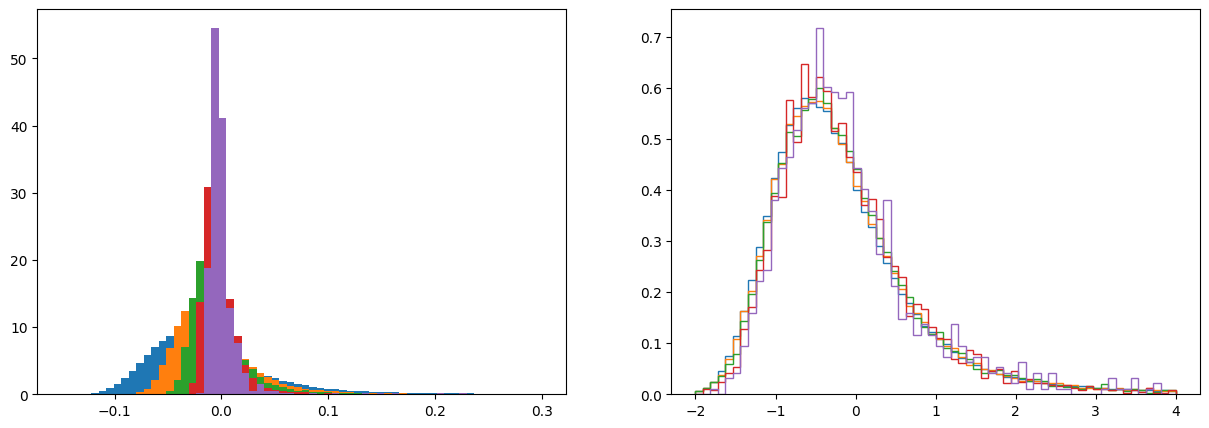

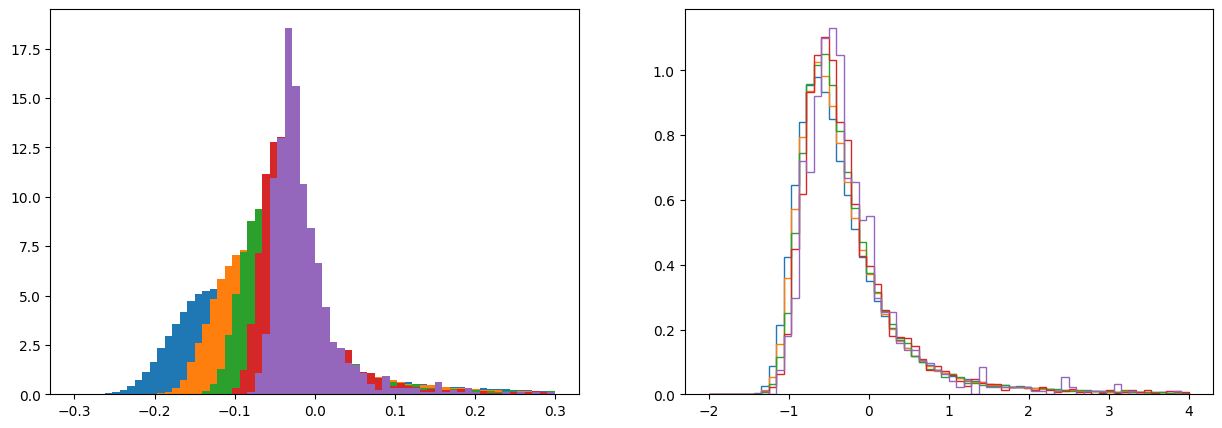

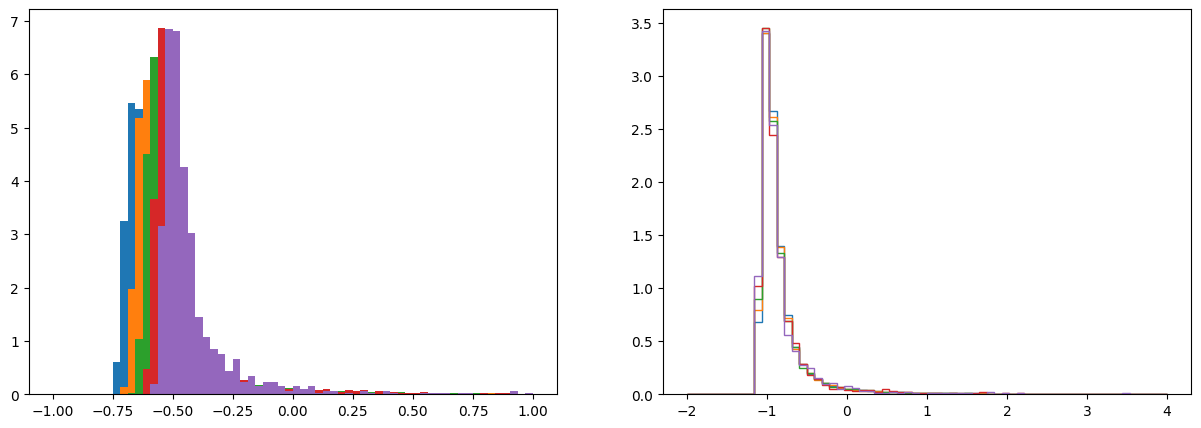

In [ ]:
alpha = 3.05
p = 0.9
NBins = 64
media = p * (alpha - 1)/(alpha - 2) + (1-p) * alpha/(alpha - 1)
fig, ax = plt.subplots(1,2, figsize=(15,5))
for n in 4**np.arange(6,11):
    m = myp305.build_average(n)
    ax[0].hist(m/media - 1 , bins=NBins, range=(-0.06,0.06),density=True, label="n = "+str(n))
    ax[1].hist((m/media  - 1)*n**(0.5) , bins=NBins, range=(-5,6),density=True,histtype='step', label="n = "+str(n))
ax[0].legend()
ax[1].legend()

alpha = 2.80
media = p * (alpha - 1)/(alpha - 2) + (1-p) * alpha/(alpha - 1)
fig, ax = plt.subplots(1,2, figsize=(15,5))
for n in 4**np.arange(6,11):
    m = myp280.build_average(n)
    ax[0].hist(m/media - 1 , bins=NBins, range=(-0.1,0.2),density=True)
    ax[1].hist((m/media  - 1)*n**(0.4) , bins=NBins, range=(-4,5),density=True,histtype='step')

alpha = 2.55
media = p * (alpha - 1)/(alpha - 2) + (1-p) * alpha/(alpha - 1)
fig, ax = plt.subplots(1,2, figsize=(15,5))
for n in 4**np.arange(6,11):
    m = myp255.build_average(n)
    ax[0].hist(m/media - 1 , bins=NBins, range=(-0.15,0.3),density=True)
    ax[1].hist((m/media  - 1)*n**(0.33) , bins=NBins, range=(-2,4),density=True,histtype='step')

alpha = 2.30
media = p * (alpha - 1)/(alpha - 2) + (1-p) * alpha/(alpha - 1)
fig, ax = plt.subplots(1,2, figsize=(15,5))
for n in 4**np.arange(6,11):
    m = myp230.build_average(n)
    ax[0].hist(m/media - 1 , bins=NBins, range=(-0.3,0.3),density=True)
    ax[1].hist((m/media  - 1)*n**(0.2) , bins=NBins, range=(-2,4),density=True,histtype='step')

alpha = 2.05
media = p * (alpha - 1)/(alpha - 2) + (1-p) * alpha/(alpha - 1)
fig, ax = plt.subplots(1,2, figsize=(15,5))
for n in 4**np.arange(6,11):
    m = myp205.build_average(n)
    ax[0].hist(m/media - 1 , bins=NBins, range=(-1,1),density=True)
    ax[1].hist((m/media  - 1)*n**(0.05) , bins=NBins, range=(-2,4),density=True,histtype='step')



### 3.5 Is there a statistical explanation for the measurements?

A dúvida sobre a existência de uma explicação estatística faz sentido. Se a distribuição tiver caudas pesadas e valor médio definido, o máximo da distribuição do estimador pode estar muito desviada do valor médio. No caso de $2.< \alpha < 3 $ as caudas são muito pesadas, o valor médio está definido mas a variância diverge. Isto implica que o teorema do limite central não se aplica e por isso a distribuição do estimador da média nunca irá estar centrada no valor médio. Neste caso o valor mais provável derá sempre inferior. 